# Machine Learning-Based Predictive Modeling for Early Detection of Subclinical Mastitis

## Version 2 – Dataset Analysis and Model Development

### 01. Dataset Loading and Initial Validation

Objective:
To load the synthetic mastitis dataset and examine its structure,
data types, missing values, duplicate records, and target distribution.

In [1]:

# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================
# 2. LOCATE PROJECT DATASET
# ============================================

file_name = "raw_mastitis_dataset.csv"

possible_paths = [
    Path("data/raw") / file_name,
    Path("../data/raw") / file_name
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"{file_name} not found. Check your project directory."
    )

print("Dataset location:", DATA_PATH.resolve())

# ============================================
# 3. LOAD DATASET
# ============================================

df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")

# ============================================
# 4. INITIAL DATASET INFORMATION
# ============================================

print("\nDataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

# ============================================
# 5. DATA QUALITY CHECKS
# ============================================

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))

# ============================================
# 6. TARGET DISTRIBUTION
# ============================================

target_column = "mastitis_label"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' not found."
    )

print("\nTarget Distribution:")
print(df[target_column].value_counts())

print("\nTarget Distribution (%):")
print(
    df[target_column]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Dataset location: C:\Users\tndar\OneDrive\Desktop\subclinical-mastitis-prediction\data\raw\raw_mastitis_dataset.csv

Dataset loaded successfully!

Dataset Shape: (2500, 14)

First 5 Records:


,cow_id,parity,days_in_milk,somatic_cell_count,milk_conductivity,milk_yield,milk_pH,udder_skin_temp,rectal_temp,activity_steps,heart_rate,ambient_temp,ambient_humidity,mastitis_label
0,C1000,3,230,191609,5.167551,23.622659,6.501671,36.718925,38.647362,5269,55,29.845943,68.614537,0
1,C1001,4,225,347013,6.461887,13.760527,7.110496,37.520745,38.920202,4313,75,35.070449,65.185501,1
2,C1002,5,215,119134,5.409023,20.169481,6.715013,36.659539,38.258309,5572,56,31.171426,56.431338,0
3,C1003,3,29,122254,6.010424,31.522919,6.663056,36.799796,38.411432,5771,61,25.491799,68.596591,0
4,C1004,1,20,194854,5.313306,35.539511,6.697970,36.820668,37.919844,6353,56,26.472922,64.197389,0



Column Names:
['cow_id', 'parity', 'days_in_milk', 'somatic_cell_count', 'milk_conductivity', 'milk_yield', 'milk_pH', 'udder_skin_temp', 'rectal_temp', 'activity_steps', 'heart_rate', 'ambient_temp', 'ambient_humidity', 'mastitis_label']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cow_id              2500 non-null   str    
 1   parity              2500 non-null   int64  
 2   days_in_milk        2500 non-null   int64  
 3   somatic_cell_count  2500 non-null   int64  
 4   milk_conductivity   2500 non-null   float64
 5   milk_yield          2500 non-null   float64
 6   milk_pH             2500 non-null   float64
 7   udder_skin_temp     2500 non-null   float64
 8   rectal_temp         2500 non-null   float64
 9   activity_steps      2500 non-null   int64  
 10  heart_rate          2500 non-null   int64  
 11  

,cow_id,parity,days_in_milk,somatic_cell_count,milk_conductivity,milk_yield,milk_pH,udder_skin_temp,rectal_temp,activity_steps,heart_rate,ambient_temp,ambient_humidity,mastitis_label
count,2500,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
unique,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,C1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,3.020400,150.85720,230197.507200,5.456721,22.930756,6.660880,36.762539,38.436404,5244.858400,64.949600,28.107126,65.212874,0.201600
std,NaN,1.412792,84.65526,234186.824518,0.605570,5.512216,0.161161,0.597196,0.415774,1237.123041,7.901749,3.995861,10.093780,0.401275
min,NaN,1.000000,5.00000,50005.000000,4.355017,5.589167,6.228222,35.160365,37.305612,2001.000000,55.000000,14.497765,28.804579,0.000000
25%,NaN,2.000000,79.00000,95205.500000,5.056008,19.255916,6.554603,36.358895,38.149654,4668.750000,59.000000,25.318946,58.354652,0.000000
50%,NaN,3.000000,150.00000,141756.000000,5.290207,23.568977,6.635360,36.590846,38.387639,5442.500000,64.000000,28.138451,65.141055,0.000000
75%,NaN,4.000000,222.00000,190466.250000,5.671007,26.817636,6.729773,36.988138,38.667732,6191.000000,68.000000,30.898961,72.044929,0.000000



Target Distribution:
mastitis_label
0    1996
1     504
Name: count, dtype: int64

Target Distribution (%):
mastitis_label
0    79.84
1    20.16
Name: proportion, dtype: float64


In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.7 MB 707.2 kB/s eta 0:00:15
   - -------------------------------------- 0.5/10.7 MB 707.2 kB/s eta 0:00:15
   - -------------------------------------- 0.5/10.7 MB 707.2 kB/s eta 0:00:15
   -- ------------------------------------- 0.8/10.7 MB 614.1 kB/s eta 0:00:17
   -- ------------------------------------- 0.8/10.7 MB 614.1 kB/s eta 0:00:17
   --- ------------------------------------ 1.0/10.7 MB 616.2 kB/s eta 0:00:16
   ---- ----------------------------------- 1.3/10.7 MB 692.8 kB/s eta 0:00:14
   ----- ---------------------------------- 1.6/10.7 MB 767.0 kB/s eta 0:00:12
   ------ --------------


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ============================================
# DATA QUALITY VALIDATION
# ============================================

print("1. COLUMN DATA TYPES")
print(df.dtypes)

print("\n2. MISSING VALUES")
print(df.isnull().sum())

print("\n3. TOTAL MISSING VALUES")
print(df.isnull().sum().sum())

print("\n4. DUPLICATE RECORDS")
print(df.duplicated().sum())

print("\n5. UNIQUE COW IDs")
print("Unique cows:", df["cow_id"].nunique())

print("\n6. TARGET DISTRIBUTION")
print(df["mastitis_label"].value_counts())

print("\n7. TARGET DISTRIBUTION (%)")
print(
    df["mastitis_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\n8. STATISTICAL SUMMARY")
display(df.describe().T)

1. COLUMN DATA TYPES
cow_id                    str
parity                  int64
days_in_milk            int64
somatic_cell_count      int64
milk_conductivity     float64
milk_yield            float64
milk_pH               float64
udder_skin_temp       float64
rectal_temp           float64
activity_steps          int64
heart_rate              int64
ambient_temp          float64
ambient_humidity      float64
mastitis_label          int64
dtype: object

2. MISSING VALUES
cow_id                0
parity                0
days_in_milk          0
somatic_cell_count    0
milk_conductivity     0
milk_yield            0
milk_pH               0
udder_skin_temp       0
rectal_temp           0
activity_steps        0
heart_rate            0
ambient_temp          0
ambient_humidity      0
mastitis_label        0
dtype: int64

3. TOTAL MISSING VALUES
0

4. DUPLICATE RECORDS
0

5. UNIQUE COW IDs
Unique cows: 2500

6. TARGET DISTRIBUTION
mastitis_label
0    1996
1     504
Name: count, dtype: int64

7. 

,count,mean,std,min,25%,50%,75%,max
parity,2500.0,3.020400,1.412792,1.000000,2.000000,3.000000,4.000000,5.000000
days_in_milk,2500.0,150.857200,84.655260,5.000000,79.000000,150.000000,222.000000,299.000000
somatic_cell_count,2500.0,230197.507200,234186.824518,50005.000000,95205.500000,141756.000000,190466.250000,998093.000000
milk_conductivity,2500.0,5.456721,0.605570,4.355017,5.056008,5.290207,5.671007,7.488440
milk_yield,2500.0,22.930756,5.512216,5.589167,19.255916,23.568977,26.817636,38.487283
milk_pH,2500.0,6.660880,0.161161,6.228222,6.554603,6.635360,6.729773,7.351698
udder_skin_temp,2500.0,36.762539,0.597196,35.160365,36.358895,36.590846,36.988138,38.675802
rectal_temp,2500.0,38.436404,0.415774,37.305612,38.149654,38.387639,38.667732,40.024291
activity_steps,2500.0,5244.858400,1237.123041,2001.000000,4668.750000,5442.500000,6191.000000,6998.000000
heart_rate,2500.0,64.949600,7.901749,55.000000,59.000000,64.000000,68.000000,89.000000


## 02. Exploratory Data Analysis (EDA)

### 2.1 Target Distribution and Feature Relationships

Objective:
To examine class distribution, feature correlations, and
potential relationships between input variables and the target.

Matplotlib is building the font cache; this may take a moment.


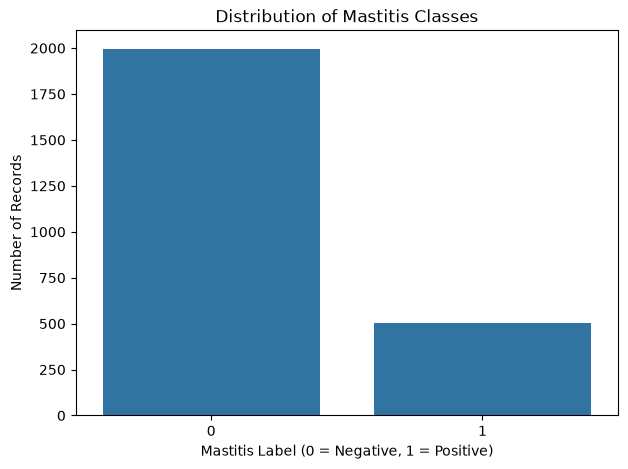

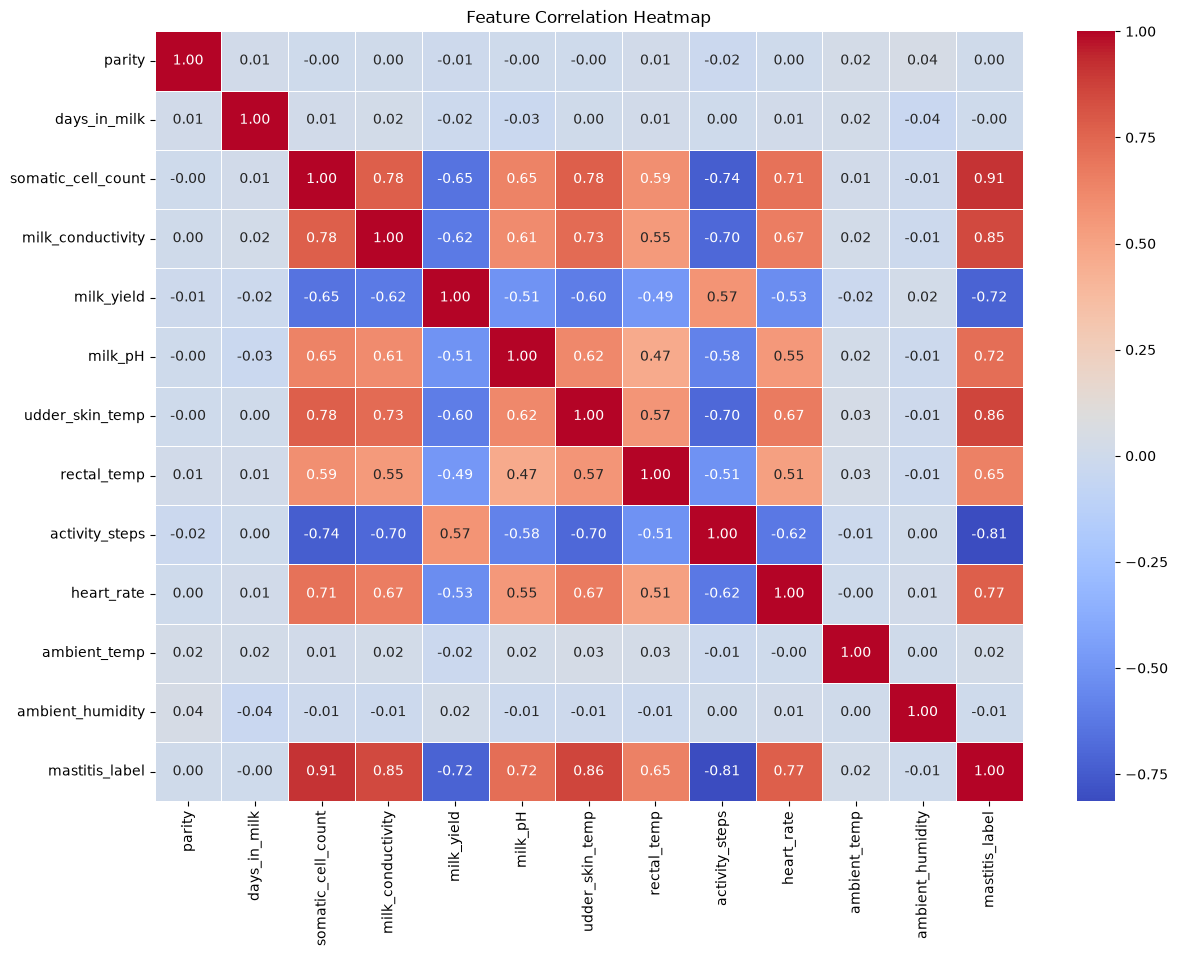

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="mastitis_label"
)

plt.title("Distribution of Mastitis Classes")
plt.xlabel("Mastitis Label (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Records")

plt.show()


# Feature correlation analysis
numeric_df = df.drop(columns=["cow_id"])

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

### 2.2 Comparison of Clinical Measurements Across Mastitis Classes

Objective:
To compare the average and median values of each numerical
feature between mastitis-negative and mastitis-positive records.

In [4]:
# Compare numerical features by target class

features = [
    "somatic_cell_count",
    "milk_conductivity",
    "milk_yield",
    "milk_pH",
    "udder_skin_temp",
    "rectal_temp",
    "activity_steps",
    "heart_rate",
    "ambient_temp",
    "ambient_humidity"
]

class_comparison = df.groupby("mastitis_label")[features].agg(
    ["mean", "median", "std", "min", "max"]
)

display(class_comparison.T.round(2))

mastitis_label                     0          1
somatic_cell_count mean    123338.97  653391.23
                   median  122735.50  655720.00
                   std      43414.93  200590.02
                   min      50005.00  300559.00
                   max     199979.00  998093.00
milk_conductivity  mean         5.20       6.48
                   median       5.19       6.47
                   std          0.30       0.38
                   min          4.36       5.15
                   max          6.23       7.49
milk_yield         mean        24.92      15.07
                   median      24.82      15.02
                   std          4.04       2.94
                   min         11.32       5.59
                   max         38.49      22.94
milk_pH            mean         6.60       6.89
                   median       6.60       6.89
                   std          0.10       0.15
                   min          6.23       6.23
                   max          6.93       7.35
udder_skin_temp    mean        36.50      37.79
                   median      36.49      37.80
                   std          0.30       0.31
                   min         35.16      36.84
                   max         37.56      38.68
rectal_temp        mean        38.30      38.97
                   median      38.30      38.96
                   std          0.30       0.37
                   min         37.31      38.07
                   max         39.29      40.02
activity_steps     mean      5750.83    3241.05
                   median    5756.00    3259.00
                   std        716.40     727.32
                   min       4500.00    2001.00
                   max       6998.00    4488.00
heart_rate         mean        61.88      77.12
                   median      62.00      77.00
                   std          4.34       7.06
                   min         55.00      65.00
                   max         69.00      89.00
ambient_temp       mean        28.07      28.27
                   median      28.07      28.57
                   std          3.99       4.01
                   min         14.63      14.50
                   max         41.88      38.95
ambient_humidity   mean        65.24      65.09
                   median      65.07      65.31
                   std         10.22       9.59
                   min         28.80      40.50
                   max         97.95      91.39

### 2.3 Feature Distribution Across Mastitis Classes

Objective:
To visualize the distribution and overlap of important numerical
features across mastitis-negative and mastitis-positive records.

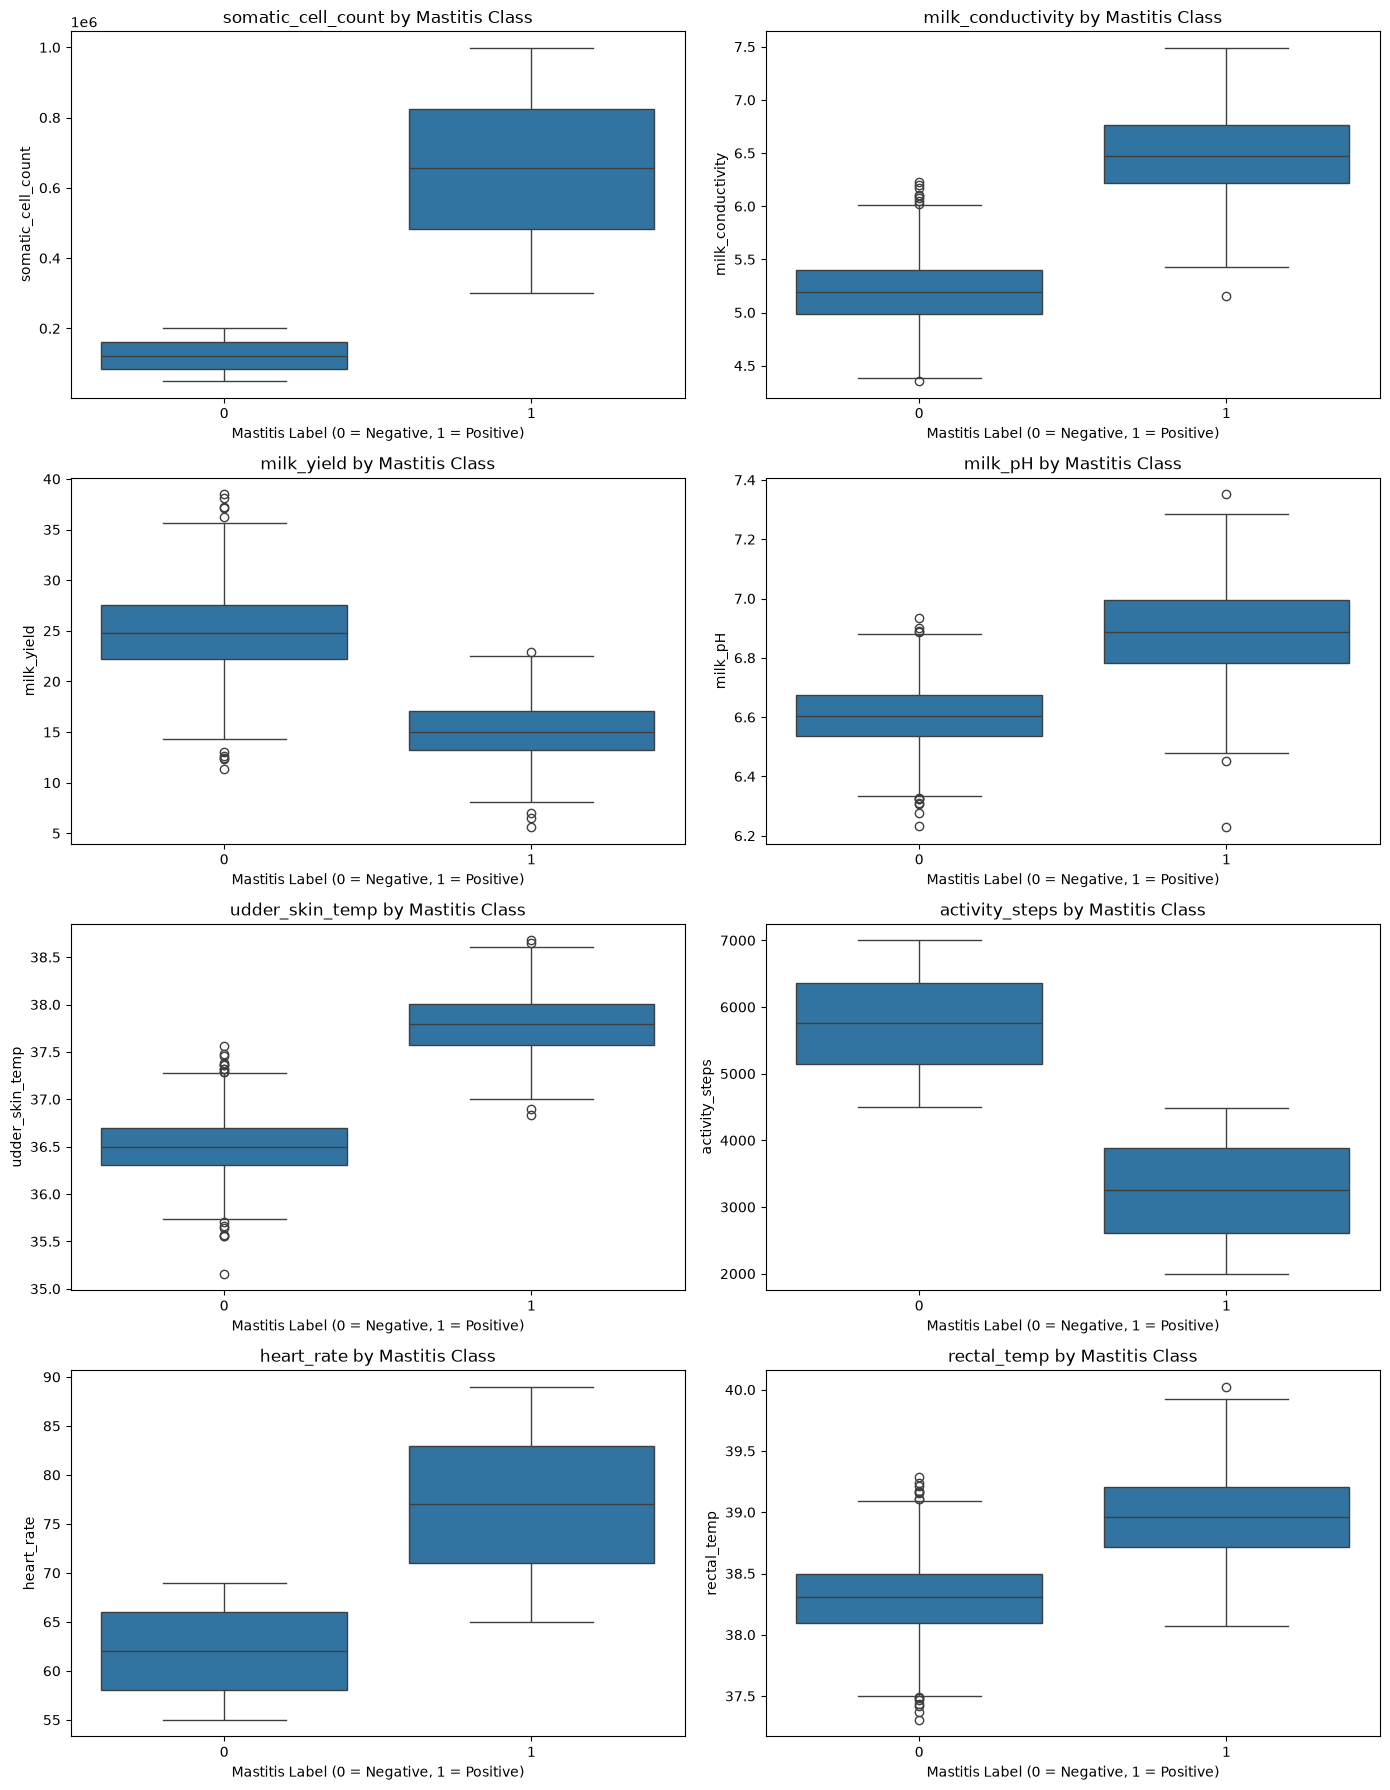

In [5]:
# Select important features for visualization

selected_features = [
    "somatic_cell_count",
    "milk_conductivity",
    "milk_yield",
    "milk_pH",
    "udder_skin_temp",
    "activity_steps",
    "heart_rate",
    "rectal_temp"
]

# Create boxplots
fig, axes = plt.subplots(4, 2, figsize=(14, 18))

axes = axes.flatten()

for i, feature in enumerate(selected_features):

    sns.boxplot(
        data=df,
        x="mastitis_label",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} by Mastitis Class")
    axes[i].set_xlabel("Mastitis Label (0 = Negative, 1 = Positive)")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

In [6]:
# Check feature ranges for each target class

features_to_check = [
    "somatic_cell_count",
    "milk_conductivity",
    "activity_steps",
    "heart_rate",
    "udder_skin_temp"
]

for feature in features_to_check:

    print(f"\nFeature: {feature}")

    for label in sorted(df["mastitis_label"].unique()):

        values = df.loc[
            df["mastitis_label"] == label,
            feature
        ]

        print(
            f"Class {label}: "
            f"Min = {values.min():.2f}, "
            f"Max = {values.max():.2f}, "
            f"Mean = {values.mean():.2f}"
        )


Feature: somatic_cell_count
Class 0: Min = 50005.00, Max = 199979.00, Mean = 123338.97
Class 1: Min = 300559.00, Max = 998093.00, Mean = 653391.23

Feature: milk_conductivity
Class 0: Min = 4.36, Max = 6.23, Mean = 5.20
Class 1: Min = 5.15, Max = 7.49, Mean = 6.48

Feature: activity_steps
Class 0: Min = 4500.00, Max = 6998.00, Mean = 5750.83
Class 1: Min = 2001.00, Max = 4488.00, Mean = 3241.05

Feature: heart_rate
Class 0: Min = 55.00, Max = 69.00, Mean = 61.88
Class 1: Min = 65.00, Max = 89.00, Mean = 77.12

Feature: udder_skin_temp
Class 0: Min = 35.16, Max = 37.56, Mean = 36.50
Class 1: Min = 36.84, Max = 38.68, Mean = 37.79


### 2.4 EDA Findings and Dataset Limitations

1. The dataset contains 2,500 records and 14 columns.
2. The target variable is binary, with approximately 79.84%
   negative and 20.16% positive records.
3. Somatic cell count and activity steps show complete
   separation between the two target classes.
4. Milk conductivity, heart rate, and udder skin temperature
   show partial overlap.
5. Several numerical features have strong correlations with
   the target variable.
6. These patterns suggest possible rule-based label generation
   in the synthetic dataset.
7. The dataset is suitable for developing and testing an
   ML engineering pipeline, but cannot establish clinical
   validity or real-world generalization.

**Limitation:** The original AI dataset-generation prompt and
label-generation rules are unavailable. Therefore, the exact
label-generation mechanism cannot be verified.

### Dataset Provenance and Limitations

- Dataset size: 2,500 records.
- Dataset origin: AI-generated synthetic dataset.
- Original generation prompt: Unavailable.
- Label-generation rules: Unknown and unverifiable.
- Real-world clinical validation: Not established.

The dataset will be used for software engineering, exploratory
analysis, and experimental ML pipeline development.

Model performance obtained using this dataset must not be
interpreted as evidence of clinical diagnostic accuracy or
generalization to real dairy herds.

In [7]:
# ============================================
# SINGLE-FEATURE RULE-BASED DIAGNOSTIC
# ============================================

from sklearn.metrics import accuracy_score, confusion_matrix

# Thresholds derived from the observed class ranges
rules = {
    "somatic_cell_count": {
        "threshold": 250269,
        "positive_if": "greater"
    },
    "activity_steps": {
        "threshold": 4494,
        "positive_if": "less"
    }
}

for feature, rule in rules.items():

    threshold = rule["threshold"]

    if rule["positive_if"] == "greater":
        predictions = (
            df[feature] > threshold
        ).astype(int)

    else:
        predictions = (
            df[feature] < threshold
        ).astype(int)

    accuracy = accuracy_score(
        df["mastitis_label"],
        predictions
    )

    print(f"\nFeature: {feature}")
    print("Threshold:", threshold)
    print("Diagnostic Accuracy:", round(accuracy * 100, 2), "%")
    print("Confusion Matrix:")
    print(confusion_matrix(
        df["mastitis_label"],
        predictions
    ))
    


Feature: somatic_cell_count
Threshold: 250269
Diagnostic Accuracy: 100.0 %
Confusion Matrix:
[[1996    0]
 [   0  504]]

Feature: activity_steps
Threshold: 4494
Diagnostic Accuracy: 100.0 %
Confusion Matrix:
[[1996    0]
 [   0  504]]


### 2.5 Investigation of Synthetic Label Separability

A rule-based diagnostic experiment was performed using
somatic_cell_count and activity_steps independently.

Both features achieved 100% in-sample classification accuracy
when thresholds were derived from the observed class ranges.

Confusion matrices showed zero classification errors.

This indicates complete class separation in the current
synthetic dataset using either feature independently.

The result raises a strong concern that the target labels
may have been generated using deterministic feature-based
rules.

The experiment is diagnostic only and must not be interpreted
as independent model validation or clinical evidence.

Further model development will use this dataset strictly
for ML pipeline engineering and demonstration.

## 03. Dataset Preparation and Train-Test Splitting

### 3.1 Separating Features and Target

Objective:
To separate independent variables (features) from the target
variable and exclude non-predictive identifiers.

### 3.2 Stratified Train-Test Split

The dataset will be divided into:
- 80% training data
- 20% testing data

Stratification will preserve the original target-class proportions.
A fixed random state will ensure reproducibility.

In [8]:
# ============================================
# 1. IMPORT REQUIRED LIBRARY
# ============================================

from sklearn.model_selection import train_test_split

# ============================================
# 2. DEFINE TARGET AND INPUT FEATURES
# ============================================

TARGET = "mastitis_label"

# Exclude target and cow identifier
X = df.drop(columns=["mastitis_label", "cow_id"])

y = df[TARGET]

# ============================================
# 3. TRAIN-TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ============================================
# 4. VERIFY DATASET SHAPES
# ============================================

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# ============================================
# 5. VERIFY CLASS DISTRIBUTION
# ============================================

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTraining Class Distribution (%):")
print(
    y_train.value_counts(normalize=True).mul(100).round(2)
)

print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nTesting Class Distribution (%):")
print(
    y_test.value_counts(normalize=True).mul(100).round(2)
)

# ============================================
# 6. VERIFY FEATURE COLUMNS
# ============================================

print("\nModel Input Features:")
print(X_train.columns.tolist())

print("\nTrain-Test Split Completed Successfully!")


Training Features: (2000, 12)
Testing Features: (500, 12)
Training Target: (2000,)
Testing Target: (500,)

Training Class Distribution:
mastitis_label
0    1597
1     403
Name: count, dtype: int64

Training Class Distribution (%):
mastitis_label
0    79.85
1    20.15
Name: proportion, dtype: float64

Testing Class Distribution:
mastitis_label
0    399
1    101
Name: count, dtype: int64

Testing Class Distribution (%):
mastitis_label
0    79.8
1    20.2
Name: proportion, dtype: float64

Model Input Features:
['parity', 'days_in_milk', 'somatic_cell_count', 'milk_conductivity', 'milk_yield', 'milk_pH', 'udder_skin_temp', 'rectal_temp', 'activity_steps', 'heart_rate', 'ambient_temp', 'ambient_humidity']

Train-Test Split Completed Successfully!


### 3.3 Building a Reusable Preprocessing Pipeline

Objective:
To create a consistent preprocessing workflow for numerical
features using median imputation and standard scaling.

The preprocessing steps will be fitted using training data only.

In [9]:
# ============================================
# IMPORT PREPROCESSING TOOLS
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# ============================================
# IDENTIFY NUMERICAL FEATURES
# ============================================

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical features:", numerical_features)

# ============================================
# CREATE NUMERICAL PREPROCESSOR
# ============================================

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ============================================
# CREATE COLUMN TRANSFORMER
# ============================================

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features)
    ],
    remainder="drop"
)

print("\nPreprocessing pipeline created successfully!")

Numerical features: ['parity', 'days_in_milk', 'somatic_cell_count', 'milk_conductivity', 'milk_yield', 'milk_pH', 'udder_skin_temp', 'rectal_temp', 'activity_steps', 'heart_rate', 'ambient_temp', 'ambient_humidity']

Preprocessing pipeline created successfully!


## 04. Baseline Model Development

### 4.1 Logistic Regression

Objective:
To establish a baseline binary classification model using
Logistic Regression and the numerical preprocessing pipeline.

The model will be trained using training data only.

In [10]:
# ============================================
# IMPORT LOGISTIC REGRESSION
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# ============================================
# CREATE BASELINE MODEL PIPELINE
# ============================================

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# ============================================
# TRAIN MODEL
# ============================================

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

# ============================================
# TRAINING SCORE
# ============================================

train_accuracy = logistic_model.score(X_train, y_train)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")


Logistic Regression training completed!
Training Accuracy: 100.0 %


### 4.2 Baseline Model Cross-Validation

Objective:
To evaluate the consistency of Logistic Regression using
Stratified 5-Fold Cross-Validation on training data.

The test dataset will remain untouched.

In [11]:
# ============================================
# STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================

from sklearn.model_selection import StratifiedKFold, cross_validate

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring_metrics,
    n_jobs=-1
)

# ============================================
# DISPLAY CROSS-VALIDATION RESULTS
# ============================================

for metric in scoring_metrics:

    scores = cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold scores:", scores.round(4))
    print("Mean:", round(scores.mean(), 4))
    print("Standard Deviation:", round(scores.std(), 4))


ACCURACY
Fold scores: [1. 1. 1. 1. 1.]
Mean: 1.0
Standard Deviation: 0.0

PRECISION
Fold scores: [1. 1. 1. 1. 1.]
Mean: 1.0
Standard Deviation: 0.0

RECALL
Fold scores: [1. 1. 1. 1. 1.]
Mean: 1.0
Standard Deviation: 0.0

F1
Fold scores: [1. 1. 1. 1. 1.]
Mean: 1.0
Standard Deviation: 0.0

ROC_AUC
Fold scores: [1. 1. 1. 1. 1.]
Mean: 1.0
Standard Deviation: 0.0


## 05. Comparative Model Evaluation

### 5.1 Comparing Multiple Classification Algorithms

Objective:
To evaluate different classification algorithms using
Stratified 5-Fold Cross-Validation.

All models will be evaluated using training data only.

In [12]:
# ============================================
# IMPORT MODELS
# ============================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.base import clone
import pandas as pd

# ============================================
# DEFINE MODELS
# ============================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# ============================================
# EVALUATE MODELS
# ============================================

results = []

for model_name, classifier in models.items():

    model_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC AUC": scores["test_roc_auc"].mean()
    })

# ============================================
# DISPLAY RESULTS
# ============================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0,1.0
3,Extra Trees,1.0,1.0,1.0,1.0,1.0
4,SVM,1.0,1.0,1.0,1.0,1.0
5,KNN,1.0,1.0,1.0,1.0,1.0
6,Gradient Boosting,1.0,1.0,1.0,1.0,1.0


### 5.2 Feature Ablation Experiment

Objective:
To investigate the influence of somatic_cell_count and
activity_steps on classification performance.

The two features will be temporarily excluded to determine
whether the remaining features retain predictive information.

This is a diagnostic experiment to investigate synthetic
label separability.

In [13]:
# ============================================
# REMOVE TWO PERFECTLY SEPARATING FEATURES
# ============================================

features_to_remove = [
    "somatic_cell_count",
    "activity_steps"
]

X_train_reduced = X_train.drop(
    columns=features_to_remove
)

print("Original feature count:", X_train.shape[1])
print("Reduced feature count:", X_train_reduced.shape[1])

# ============================================
# COMPARE MODELS USING REMAINING FEATURES
# ============================================

ablation_results = []

for model_name, classifier in models.items():

    reduced_preprocessor = clone(preprocessor).set_params(
        transformers=[
            (
                "num",
                clone(numerical_pipeline),
                X_train_reduced.columns.tolist()
            )
        ]
    )

    model_pipeline = Pipeline(steps=[
        ("preprocessor", reduced_preprocessor),
        ("classifier", clone(classifier))
    ])

    scores = cross_validate(
        model_pipeline,
        X_train_reduced,
        y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1
    )

    ablation_results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC AUC": scores["test_roc_auc"].mean()
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

Original feature count: 12
Reduced feature count: 10


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000
1,Decision Tree,0.9975,0.9951,0.9926,0.9938,0.9957
2,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
3,Extra Trees,1.0000,1.0000,1.0000,1.0000,1.0000
4,SVM,1.0000,1.0000,1.0000,1.0000,1.0000
5,KNN,0.9995,1.0000,0.9975,0.9988,1.0000
6,Gradient Boosting,0.9965,0.9951,0.9876,0.9913,0.9984


### 5.3 Feature Ablation Results and Interpretation

An ablation experiment was conducted by removing
somatic_cell_count and activity_steps from the training features.

The remaining ten features were evaluated using stratified
five-fold cross-validation.

Results:
- Logistic Regression: 100% accuracy
- Decision Tree: 99.75% accuracy
- Random Forest: 100% accuracy
- Extra Trees: 100% accuracy
- SVM: 100% accuracy
- KNN: 99.95% accuracy
- Gradient Boosting: 99.65% accuracy

The results indicate that strong class separability remains
even after removing the two previously identified features.

This suggests that multiple features may encode the
synthetic target-generation patterns.

These results are experimental findings on synthetic data
and do not establish real-world clinical performance.

## 06. Model Interpretability and Feature Importance

### 6.1 Random Forest Feature Importance

Objective:
To identify the relative contribution of each input feature
to the Random Forest classification model.

The model will be trained using the reduced training dataset.

Random Forest training completed!


,Feature,Importance
5,udder_skin_temp,0.3553
2,milk_conductivity,0.2668
7,heart_rate,0.1853
3,milk_yield,0.0935
4,milk_pH,0.0696
6,rectal_temp,0.0272
8,ambient_temp,0.0008
1,days_in_milk,0.0006
9,ambient_humidity,0.0005
0,parity,0.0003


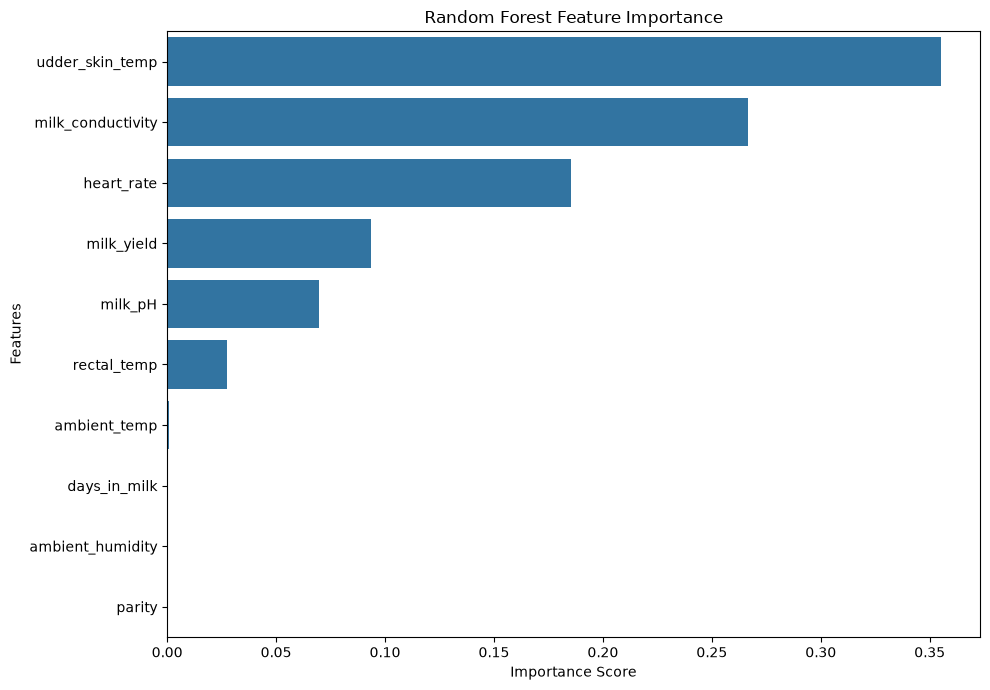

In [14]:
# ============================================
# IMPORT RANDOM FOREST
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# CREATE RANDOM FOREST PIPELINE
# ============================================

rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor).set_params(
        transformers=[
            (
                "num",
                clone(numerical_pipeline),
                X_train_reduced.columns.tolist()
            )
        ]
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# ============================================
# TRAIN MODEL
# ============================================

rf_pipeline.fit(X_train_reduced, y_train)

print("Random Forest training completed!")

# ============================================
# EXTRACT FEATURE IMPORTANCE
# ============================================

rf_importance = rf_pipeline.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": X_train_reduced.columns,
    "Importance": rf_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.round(4))

# ============================================
# VISUALIZE FEATURE IMPORTANCE
# ============================================

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


### 6.2 Random Forest Feature Importance Findings

The Random Forest model identified udder_skin_temp as the
most important feature, followed by milk_conductivity and
heart_rate.

The top three features collectively contributed approximately
80.74% of the model's total impurity-based feature importance.

Features such as parity, days_in_milk, ambient_temp and
ambient_humidity showed very low importance.

These findings describe the behaviour of the model on the
current synthetic dataset and should not be interpreted as
clinical evidence or causal relationships.

Further investigation using permutation importance and SHAP
will be conducted to understand model reliance.

,Feature,Importance Mean,Importance Std
7,heart_rate,0.21946,0.00389
5,udder_skin_temp,0.13752,0.00644
2,milk_conductivity,0.00806,0.00186
0,parity,0.00000,0.00000
1,days_in_milk,0.00000,0.00000
3,milk_yield,0.00000,0.00000
4,milk_pH,0.00000,0.00000
6,rectal_temp,0.00000,0.00000
8,ambient_temp,0.00000,0.00000
9,ambient_humidity,0.00000,0.00000


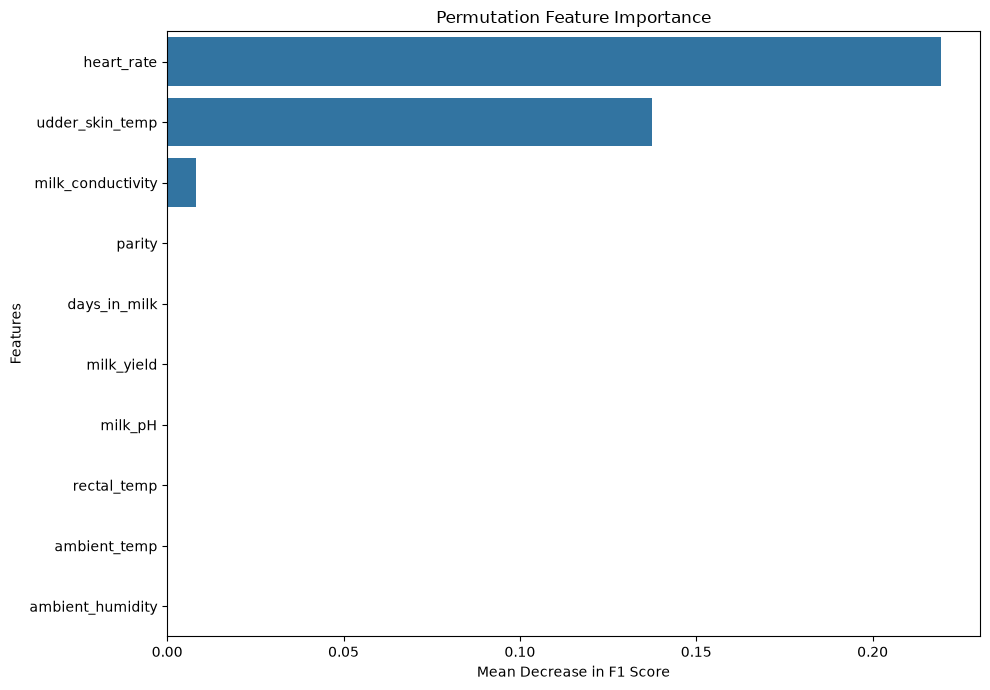

In [15]:
# ============================================
# PERMUTATION FEATURE IMPORTANCE
# ============================================

from sklearn.inspection import permutation_importance
import numpy as np

# Use the existing reduced-feature Random Forest model
rf_pipeline.fit(X_train_reduced, y_train)

# Calculate permutation importance on training data
# Note: This is an in-sample diagnostic, not an unbiased
# generalization estimate.

perm_result = permutation_importance(
    rf_pipeline,
    X_train_reduced,
    y_train,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create results table
permutation_df = pd.DataFrame({
    "Feature": X_train_reduced.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance Mean",
    ascending=False
)

display(permutation_df.round(5))

# Visualize
plt.figure(figsize=(10, 7))

sns.barplot(
    data=permutation_df,
    x="Importance Mean",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Mean Decrease in F1 Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### 6.3 Permutation Feature Importance Findings

Permutation importance was calculated using F1 score
as the evaluation metric.

The highest importance was observed for:
1. heart_rate: 0.21946
2. udder_skin_temp: 0.13752
3. milk_conductivity: 0.00806

The remaining features showed zero mean importance
in this training-data experiment.

The ranking differs from Random Forest impurity-based
importance because the methods measure different
aspects of feature contribution.

This analysis was conducted on training data and
does not establish clinical importance or causal
relationships.

### 6.4 Cross-Validated Permutation Feature Importance

Objective:
To evaluate feature importance on held-out validation
folds using Stratified 5-Fold Cross-Validation.

Completed fold 1
Completed fold 2
Completed fold 3
Completed fold 4
Completed fold 5


,Feature,Importance Mean,Importance Std
7,heart_rate,0.19951,0.01381
5,udder_skin_temp,0.15444,0.05840
2,milk_conductivity,0.01064,0.00733
6,rectal_temp,0.00360,0.00384
3,milk_yield,0.00274,0.00244
4,milk_pH,0.00175,0.00218
1,days_in_milk,0.00173,0.00346
9,ambient_humidity,0.00062,0.00124
0,parity,0.00000,0.00000
8,ambient_temp,0.00000,0.00000


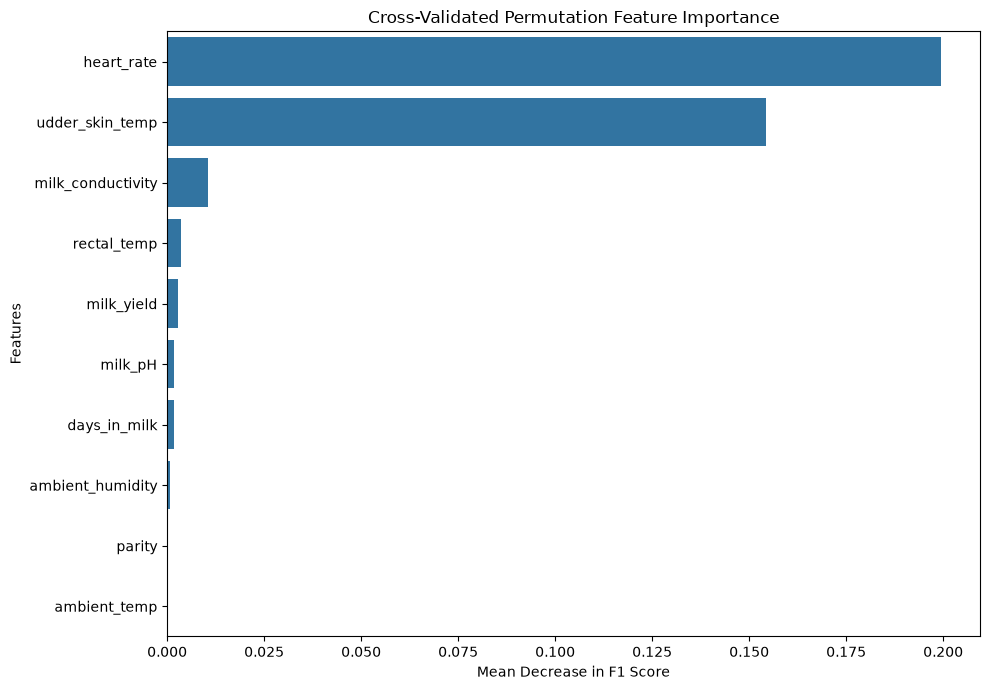

In [16]:
# ============================================
# CROSS-VALIDATED PERMUTATION IMPORTANCE
# ============================================

from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
import numpy as np
import pandas as pd

cv_importances = []

for fold, (train_idx, val_idx) in enumerate(
    cv_strategy.split(X_train_reduced, y_train), start=1
):

    X_fold_train = X_train_reduced.iloc[train_idx]
    X_fold_val = X_train_reduced.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Create a fresh model for each fold
    fold_model = clone(rf_pipeline)

    # Train on fold training data
    fold_model.fit(X_fold_train, y_fold_train)

    # Calculate importance on held-out validation data
    fold_result = permutation_importance(
        fold_model,
        X_fold_val,
        y_fold_val,
        scoring="f1",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    cv_importances.append(fold_result.importances_mean)

    print(f"Completed fold {fold}")

# ============================================
# AGGREGATE RESULTS
# ============================================

cv_importances = np.array(cv_importances)

cv_permutation_df = pd.DataFrame({
    "Feature": X_train_reduced.columns,
    "Importance Mean": cv_importances.mean(axis=0),
    "Importance Std": cv_importances.std(axis=0)
})

cv_permutation_df = cv_permutation_df.sort_values(
    by="Importance Mean",
    ascending=False
)

display(cv_permutation_df.round(5))

# ============================================
# VISUALIZATION
# ============================================

plt.figure(figsize=(10, 7))

sns.barplot(
    data=cv_permutation_df,
    x="Importance Mean",
    y="Feature"
)

plt.title("Cross-Validated Permutation Feature Importance")
plt.xlabel("Mean Decrease in F1 Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### 6.4 Cross-Validated Permutation Feature Importance Findings

Cross-validated permutation importance was calculated
using stratified five-fold cross-validation.

The most influential features were:

1. heart_rate: 0.19951
2. udder_skin_temp: 0.15444
3. milk_conductivity: 0.01064

Heart rate demonstrated the highest mean importance.

Udder skin temperature showed relatively high variation
across validation folds.

Most remaining features demonstrated very low permutation
importance.

These findings indicate that the Random Forest model
primarily relies on a small number of features.

The results are specific to the current synthetic dataset
and cannot establish clinical relevance or causality.

In [17]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 1.5 MB/s eta 0:00:00

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ----------


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP imported successfully!")


SHAP version: 0.54.1
SHAP imported successfully!


### 6.5 SHAP-Based Model Explainability

Objective:
To explain the contribution of individual input features
to Random Forest predictions using SHAP values.

The analysis uses the reduced training dataset.

In [19]:
# ============================================
# IMPORT SHAP
# ============================================

import shap
import matplotlib.pyplot as plt
import numpy as np

# ============================================
# PREPARE TRAINED RANDOM FOREST MODEL
# ============================================

# rf_pipeline was previously trained on X_train_reduced.
# Confirm that it is fitted.
print("Random Forest model is ready for SHAP analysis.")

# ============================================
# TRANSFORM TRAINING DATA
# ============================================

fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]

X_train_transformed = fitted_preprocessor.transform(
    X_train_reduced
)

# Convert transformed data into a DataFrame
X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=X_train_reduced.columns,
    index=X_train_reduced.index
)

# ============================================
# CREATE SHAP EXPLAINER
# ============================================

rf_classifier = rf_pipeline.named_steps["classifier"]

explainer = shap.TreeExplainer(rf_classifier)

print("SHAP explainer created successfully!")

Random Forest model is ready for SHAP analysis.
SHAP explainer created successfully!


In [20]:
# ============================================
# CALCULATE SHAP VALUES
# ============================================

# Select 300 training records
X_shap_sample = X_train_shap.sample(
    n=min(300, len(X_train_shap)),
    random_state=42
)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap_sample)

# ============================================
# INSPECT SHAP OUTPUT
# ============================================

print("SHAP calculation completed!")

print("\nSHAP output type:")
print(type(shap_values))

print("\nSHAP output shape:")

if isinstance(shap_values, list):
    for class_index, values in enumerate(shap_values):
        print(f"Class {class_index}:", values.shape)
else:
    print(shap_values.shape)

print("\nSample data shape:")
print(X_shap_sample.shape)

SHAP calculation completed!

SHAP output type:
<class 'numpy.ndarray'>

SHAP output shape:
(300, 10, 2)

Sample data shape:
(300, 10)


Positive class SHAP shape: (300, 10)


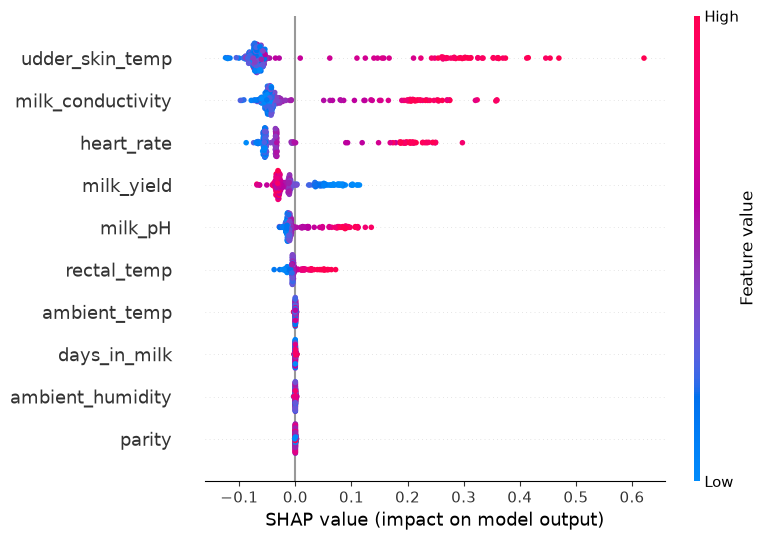

In [21]:
# ============================================
# EXTRACT CLASS 1 SHAP VALUES
# ============================================

shap_values_positive = shap_values[:, :, 1]

print("Positive class SHAP shape:", shap_values_positive.shape)

# ============================================
# SHAP SUMMARY PLOT
# ============================================

shap.summary_plot(
    shap_values_positive,
    X_shap_sample,
    feature_names=X_shap_sample.columns,
    show=True
)

Actual Class: 1
Predicted Class: 1
Predicted Class 1 Score: 1.0


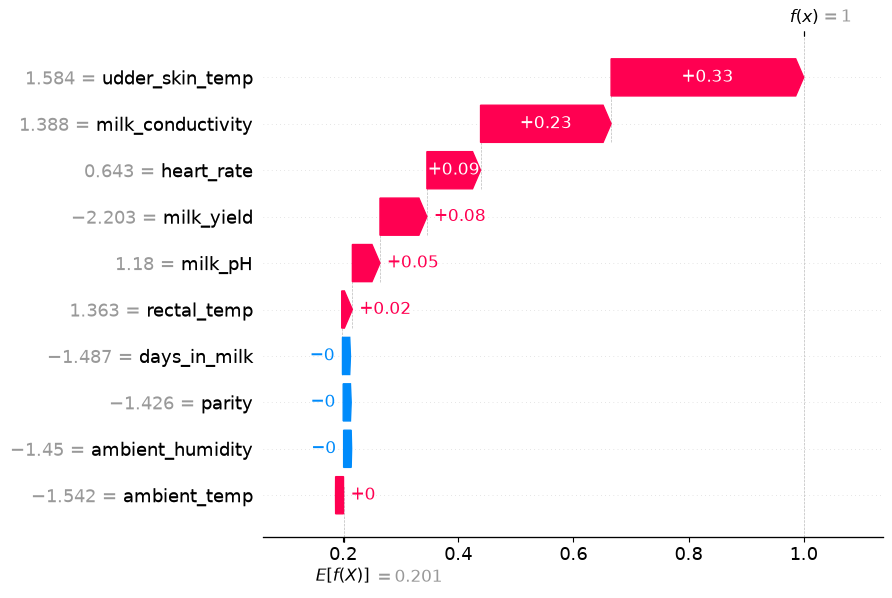

In [22]:
# ============================================
# SELECT ONE POSITIVE CLASS RECORD
# ============================================

# Find positive records in our SHAP sample
positive_candidates = X_shap_sample.index[
    y_train.loc[X_shap_sample.index] == 1
]

if len(positive_candidates) == 0:
    raise ValueError("No positive records found in SHAP sample.")

selected_index = positive_candidates[0]

# Get the position of this record in SHAP sample
row_position = X_shap_sample.index.get_loc(selected_index)

# ============================================
# GET SHAP VALUES FOR CLASS 1
# ============================================

positive_shap_values = shap_values[
    row_position, :, 1
]

# Get SHAP base value for class 1
base_value = explainer.expected_value[1]

# ============================================
# CREATE SHAP EXPLANATION
# ============================================

waterfall_explanation = shap.Explanation(
    values=positive_shap_values,
    base_values=base_value,
    data=X_shap_sample.iloc[row_position].values,
    feature_names=X_shap_sample.columns.tolist()
)

# ============================================
# DISPLAY INDIVIDUAL PREDICTION
# ============================================

selected_record = X_train_reduced.loc[[selected_index]]

prediction = rf_pipeline.predict(selected_record)[0]

print("Actual Class:", y_train.loc[selected_index])
print("Predicted Class:", prediction)
print(
    "Predicted Class 1 Score:",
    rf_pipeline.predict_proba(selected_record)[0][1]
)

# ============================================
# SHAP WATERFALL PLOT
# ============================================

shap.plots.waterfall(
    waterfall_explanation,
    max_display=10
)

### 6.6 SHAP Waterfall Plot Interpretation

A SHAP waterfall plot was generated for an individual
mastitis-positive record.

The baseline model output was approximately 0.201,
while the final model output reached approximately 1.000.

The strongest positive contributions were:

1. Udder skin temperature: +0.33
2. Milk conductivity: +0.23
3. Heart rate: +0.09
4. Milk yield: +0.08
5. Milk pH: +0.05

These features pushed the model prediction towards
the positive mastitis class.

The remaining features had negligible contributions
for this particular observation.

The analysis explains model behaviour on synthetic data
and does not establish clinical diagnostic validity.

In [23]:
%pip install optuna


   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 1.4 MB/s eta 0:00:02
   ----------------- ---------------------- 1.0/2.4 MB 1.7 MB/s eta 0:00:01
   --------------------- ------------------ 1.3/2.4 MB 1.8 MB/s eta 0:00:01
   ------------------------- -------------- 1.6/2.4 MB 1.8 MB/s eta 0:00:01
   ------------------------------ --------- 1.8/2.4 MB 1.7 MB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 1.5 MB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 1.5 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 1.3 MB/s eta 0:00:00

   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import optuna

print("Optuna version:", optuna.__version__)
print("Optuna imported successfully!")

Optuna version: 5.0.0
Optuna imported successfully!


### 7.1 Random Forest Hyperparameter Optimization Using Optuna

Objective:
To identify an effective Random Forest hyperparameter
configuration using Optuna and Stratified 5-Fold
Cross-Validation.

Optimization metric: F1 Score.

Only training data will be used during optimization.

In [25]:
# ============================================
# IMPORT REQUIRED LIBRARIES
# ============================================

import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

# ============================================
# CREATE REDUCED FEATURE PREPROCESSOR
# ============================================

reduced_preprocessor = clone(preprocessor).set_params(
    transformers=[
        (
            "num",
            clone(numerical_pipeline),
            X_train_reduced.columns.tolist()
        )
    ]
)

# ============================================
# DEFINE OPTUNA OBJECTIVE
# ============================================

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 500, step=50
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 20
        ),

        "min_samples_split": trial.suggest_int(
            "min_samples_split", 2, 20
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 10
        ),

        "max_features": trial.suggest_categorical(
            "max_features", ["sqrt", "log2", None]
        ),

        "class_weight": trial.suggest_categorical(
            "class_weight",
            [None, "balanced", "balanced_subsample"]
        ),

        "random_state": 42,
        "n_jobs": -1
    }

    # Create model pipeline
    model_pipeline = Pipeline(steps=[
        ("preprocessor", clone(reduced_preprocessor)),
        ("classifier", RandomForestClassifier(**params))
    ])

    # Evaluate using stratified cross-validation
    scores = cross_val_score(
        model_pipeline,
        X_train_reduced,
        y_train,
        cv=cv_strategy,
        scoring="f1",
        n_jobs=1
    )

    return scores.mean()


print("Optuna objective function created successfully!")

Optuna objective function created successfully!


In [26]:
# ============================================
# CREATE OPTUNA STUDY
# ============================================

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

# ============================================
# START OPTIMIZATION
# ============================================

study.optimize(
    objective,
    n_trials=30
)

# ============================================
# DISPLAY BEST RESULTS
# ============================================

print("\nOPTIMIZATION COMPLETED")

print("\nBest F1 Score:")
print(round(study.best_value, 5))

print("\nBest Hyperparameters:")

for parameter, value in study.best_params.items():
    print(f"{parameter}: {value}")

[I 2026-11-01 00:59:05,911] A new study created in memory with name: no-name-d02b2663-0f90-4eac-ab12-ca1dd8c8021c
[I 2026-11-01 00:59:08,579] Trial 0 finished with value: 0.9950611567696879 and parameters: {'n_estimators': 250, 'max_depth': 20, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'class_weight': None}. Best is trial 0 with value: 0.9950611567696879.
[I 2026-11-01 00:59:09,926] Trial 1 finished with value: 0.9888490071429432 and parameters: {'n_estimators': 100, 'max_depth': 20, 'min_samples_split': 17, 'min_samples_leaf': 3, 'max_features': None, 'class_weight': None}. Best is trial 0 with value: 0.9950611567696879.
[I 2026-11-01 00:59:13,835] Trial 2 finished with value: 0.9962730025623108 and parameters: {'n_estimators': 350, 'max_depth': 5, 'min_samples_split': 7, 'min_samples_leaf': 4, 'max_features': 'log2', 'class_weight': 'balanced'}. Best is trial 2 with value: 0.9962730025623108.
[I 2026-11-01 00:59:18,398] Trial 3 finished with value: 0.995


OPTIMIZATION COMPLETED

Best F1 Score:
0.9975

Best Hyperparameters:
n_estimators: 500
max_depth: 16
min_samples_split: 19
min_samples_leaf: 9
max_features: log2
class_weight: balanced_subsample


### 7.2 Optuna Hyperparameter Optimization Results

Optuna was used to optimize Random Forest hyperparameters
using 30 trials and stratified five-fold cross-validation.

Best F1 Score: 0.9975

Best Parameters:
- n_estimators: 500
- max_depth: 16
- min_samples_split: 19
- min_samples_leaf: 9
- max_features: log2
- class_weight: balanced_subsample

The baseline Random Forest achieved an F1 score of 1.0000,
while the optimized model achieved 0.9975.

Therefore, hyperparameter optimization did not improve
the baseline cross-validation F1 score.

Results are limited to the current synthetic dataset.

In [27]:
# ============================================
# TRAIN OPTIMIZED RANDOM FOREST
# ============================================

best_rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(reduced_preprocessor)),
    ("classifier", RandomForestClassifier(
        **study.best_params,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using reduced training features
best_rf_pipeline.fit(X_train_reduced, y_train)

print("Optimized Random Forest training completed!")

# Training score
train_predictions = best_rf_pipeline.predict(X_train_reduced)

from sklearn.metrics import accuracy_score, f1_score

print(
    "Training Accuracy:",
    round(accuracy_score(y_train, train_predictions), 4)
)

print(
    "Training F1 Score:",
    round(f1_score(y_train, train_predictions), 4)
)


Optimized Random Forest training completed!
Training Accuracy: 1.0
Training F1 Score: 1.0


In [28]:
from sklearn.model_selection import cross_validate

# Both models use the same reduced feature set and CV strategy
models_to_compare = {
    "Baseline Random Forest": rf_pipeline,
    "Optimized Random Forest": best_rf_pipeline
}

comparison_results = []

for model_name, model in models_to_compare.items():

    scores = cross_validate(
        model,
        X_train_reduced,
        y_train,
        cv=cv_strategy,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

comparison_df = pd.DataFrame(comparison_results)

print("Baseline vs Optimized Random Forest")
display(comparison_df.round(4))

Baseline vs Optimized Random Forest


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline Random Forest,1.000,1.0000,1.0000,1.0000,1.0
1,Optimized Random Forest,0.999,0.9975,0.9975,0.9975,1.0


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Prepare test data using the same reduced feature set
X_test_reduced = X_test.drop(
    columns=["somatic_cell_count", "activity_steps"]
)

# Predict using the baseline Random Forest
y_test_pred = rf_pipeline.predict(X_test_reduced)
y_test_prob = rf_pipeline.predict_proba(X_test_reduced)[:, 1]

# Calculate evaluation metrics
print("FINAL TEST SET EVALUATION")
print("-" * 40)

print("Accuracy :", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall   :", recall_score(y_test, y_test_pred))
print("F1 Score :", f1_score(y_test, y_test_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


FINAL TEST SET EVALUATION
----------------------------------------
Accuracy : 0.998
Precision: 0.9901960784313726
Recall   : 1.0
F1 Score : 0.9950738916256158
ROC-AUC  : 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       399
           1       0.99      1.00      1.00       101

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500


Confusion Matrix:
[[398   1]
 [  0 101]]


### Final Test Set Evaluation – Baseline Random Forest

The baseline Random Forest model was evaluated on the previously
reserved 20% test set containing 500 records.

| Metric | Score |
|---|---:|
| Accuracy | 99.80% |
| Precision | 99.02% |
| Recall | 100.00% |
| F1 Score | 99.51% |
| ROC-AUC | 1.0000 |

Confusion Matrix:

- True Negatives: 398
- False Positives: 1
- False Negatives: 0
- True Positives: 101

**Limitation:** The dataset is synthetic. These results demonstrate
performance on the available synthetic data and must not be interpreted
as validated clinical performance. Independent evaluation using
real-world dairy-herd data is necessary.

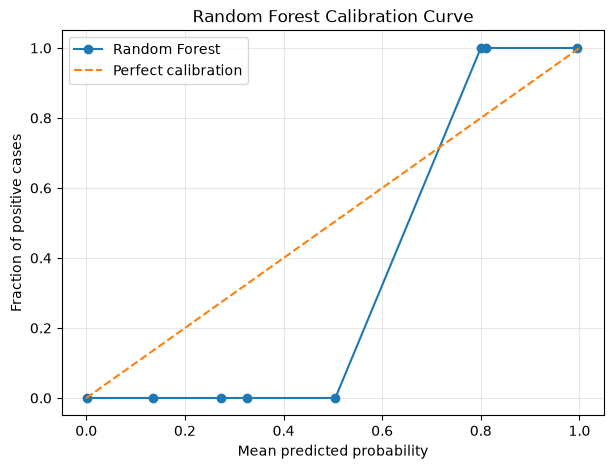

In [30]:
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    y_test_prob,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positive cases")
plt.title("Random Forest Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
calibration_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted_Probability": y_test_prob
})

calibration_df["Probability_Bin"] = pd.cut(
    calibration_df["Predicted_Probability"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True
)

calibration_summary = calibration_df.groupby(
    "Probability_Bin",
    observed=False
).agg(
    Sample_Count=("Actual", "count"),
    Mean_Predicted_Probability=("Predicted_Probability", "mean"),
    Actual_Positive_Rate=("Actual", "mean")
)

display(calibration_summary.round(4))

,Sample_Count,Mean_Predicted_Probability,Actual_Positive_Rate
Probability_Bin,,,
"(-0.001, 0.1]",391,0.0014,0.0
"(0.1, 0.2]",4,0.1350,0.0
"(0.2, 0.3]",2,0.2725,0.0
"(0.3, 0.4]",1,0.3250,0.0
"(0.4, 0.5]",0,NaN,NaN
"(0.5, 0.6]",1,0.5050,0.0
"(0.6, 0.7]",0,NaN,NaN
"(0.7, 0.8]",2,0.8000,1.0
"(0.8, 0.9]",1,0.8100,1.0


### Probability Calibration Analysis

A calibration analysis was conducted on the test-set predictions
using 10 uniform probability bins.

Most negative records received low predicted probabilities, while
most positive records received high predicted probabilities.

The intermediate probability bins contained very few observations,
making their observed positive rates statistically unstable.

No probability calibration method was applied at this stage.
The baseline Random Forest was retained as the selected candidate.

**Limitation:** Calibration results are based on a synthetic dataset
and should not be interpreted as evidence of clinical reliability.

In [32]:
import joblib

joblib.dump(rf_pipeline, "../models/baseline_random_forest.pkl")

print("Model saved successfully!")

Model saved successfully!


In [33]:
import os

print(os.path.exists("../models/baseline_random_forest.pkl"))

True
